# IND320 — Assignment 2

##  GitHub and Streamlit Links

**Name**: Prachi Kumari

**GitHub repository:** https://github.com/prakum04/IND320_Project

**GitHub branch:** `assignment-2`

**Streamlit application:** https://ind320-assignment2-prakum04.streamlit.app/

## 1. Cassandra and Spark Setup

This section establishes a connection between Apache Spark and the local Cassandra database. Spark will be used to process electricity transfer data and store it in Cassandra.

In [1]:
import os
import sys
from pathlib import Path

project_dir = Path.cwd().resolve()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

python_path = sys.executable

os.environ["PYSPARK_PYTHON"] = python_path
os.environ["PYSPARK_DRIVER_PYTHON"] = python_path

print("Python:", python_path)
print("Project:", project_dir)

Python: c:\Projects\IND320\.venv\Scripts\python.exe
Project: C:\Projects\IND320_Project


In [2]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .master("local[2]")
    .appName("IND320_Assignment_2")
    .config("spark.jars.ivy", "C:/Projects/ivy_cache")
    .config(
        "spark.jars.packages",
        "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1"
    )
    .config("spark.cassandra.connection.host", "127.0.0.1")
    .config("spark.cassandra.connection.port", "9042")
    .getOrCreate()
)

print("Spark version:", spark.version)

Spark version: 3.5.1


In [3]:
df_test = spark.read \
    .format("org.apache.spark.sql.cassandra") \
    .options(table="electricity_prices", keyspace="ind320") \
    .load()

df_test.show(5)
print("Total rows:", df_test.count())

+-------------------+-------------+--------------------+
|      timestamp_utc|price_eur_mwh|    timestamp_norway|
+-------------------+-------------+--------------------+
|2026-10-02 18:30:00|       147.43|2026-10-02 18:30:...|
|2026-10-01 08:00:00|        157.8|2026-10-01 08:00:...|
|2026-10-02 03:00:00|       127.11|2026-10-02 03:00:...|
|2026-10-02 14:15:00|        130.8|2026-10-02 14:15:...|
|2026-10-02 09:30:00|        150.3|2026-10-02 09:30:...|
+-------------------+-------------+--------------------+
only showing top 5 rows

Total rows: 189


## 2. MongoDB Atlas Connection

MongoDB Atlas is used to store processed data that will later be accessed by the Streamlit application. The connection string is stored securely in a local `.env` file.

In [4]:
import os
from dotenv import load_dotenv
from pymongo import MongoClient

load_dotenv(project_dir / ".env")

mongo_uri = os.getenv("MONGODB_URI")

if not mongo_uri:
    raise ValueError("MONGODB_URI not found in .env")

client = MongoClient(mongo_uri, serverSelectionTimeoutMS=10000)
client.admin.command("ping")

db = client["ind320"]

print("Connected to MongoDB Atlas")
print("Collections:", db.list_collection_names())

Connected to MongoDB Atlas
Collections: ['connection_test', 'daily_electricity_prices']


## 3. NVE Magasinstatistikk API

### 3.1 Download and Prepare Data

The NVE API provides historical reservoir filling statistics for Norway. The data is downloaded and converted into a Pandas DataFrame for analysis.

In [5]:
import requests
import pandas as pd

url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"

response = requests.get(url, timeout=60)
response.raise_for_status()

df_nve = pd.DataFrame(response.json())

print("Rows:", len(df_nve))
display(df_nve.head())
print(df_nve.columns.tolist())

Rows: 14922


,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301


['dato_Id', 'omrType', 'omrnr', 'iso_aar', 'iso_uke', 'fyllingsgrad', 'kapasitet_TWh', 'fylling_TWh', 'neste_Publiseringsdato', 'fyllingsgrad_forrige_uke', 'endring_fyllingsgrad']


In [6]:
df_nve = df_nve.rename(columns={
    "dato_Id": "date",
    "omrType": "area_type",
    "omrnr": "area_number",
    "fyllingsgrad": "fill_level",
    "kapasitet_TWh": "capacity_TWh",
    "fylling_TWh": "stored_energy_TWh"
})

df_nve["date"] = pd.to_datetime(df_nve["date"])
df_nve = df_nve.sort_values("date")

print("Area types:", df_nve["area_type"].unique())
print("Date range:", df_nve["date"].min(), "to", df_nve["date"].max())

display(df_nve.head())

Area types: <ArrowStringArray>
['EL', 'VASS', 'NO']
Length: 3, dtype: str
Date range: 1995-01-08 00:00:00 to 2026-10-11 00:00:00


,date,area_type,area_number,iso_aar,iso_uke,fill_level,capacity_TWh,stored_energy_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
3111,1995-01-08,EL,5,1995,1,0.616448,17.390587,10.720388,0001-01-01T00:00:00,0.614288,0.002160
11344,1995-01-08,VASS,2,1995,1,0.608856,23.237715,14.148431,0001-01-01T00:00:00,0.744693,-0.135837
11170,1995-01-08,VASS,3,1995,1,0.566906,28.155403,15.961480,0001-01-01T00:00:00,0.661432,-0.094525
14499,1995-01-08,VASS,1,1995,1,0.635440,36.044464,22.904102,0001-01-01T00:00:00,0.756482,-0.121041
9678,1995-01-08,NO,0,1995,1,0.607988,87.437580,53.161003,0001-01-01T00:00:00,0.752631,-0.144643


### 3.2 Reservoir Visualizations

The reservoir filling levels are visualized for different geographical area types (EL, NO and VASS). This helps compare historical changes in reservoir storage.

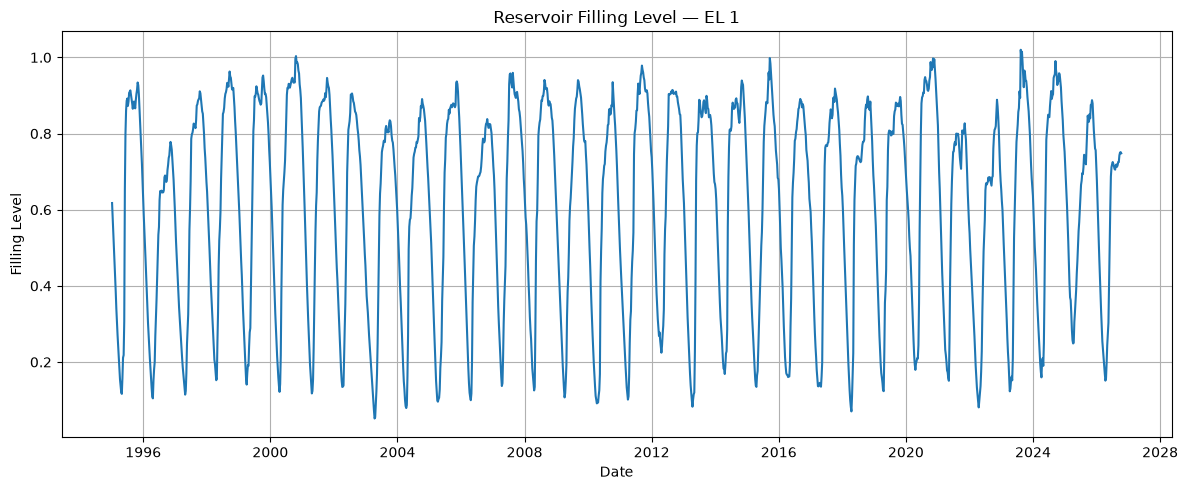

In [7]:
import matplotlib.pyplot as plt

area_type = "EL"
area_number = 1

df_plot = df_nve[
    (df_nve["area_type"] == area_type) &
    (df_nve["area_number"] == area_number)
].sort_values("date")

plt.figure(figsize=(12, 5))
plt.plot(df_plot["date"], df_plot["fill_level"])

plt.title(f"Reservoir Filling Level — {area_type} {area_number}")
plt.xlabel("Date")
plt.ylabel("Filling Level")
plt.grid(True)
plt.tight_layout()
plt.show()

## 4. ENTSO-E Cross-Border Electricity Transfers

### 4.1 API Connection

The ENTSO-E Transparency Platform provides electricity market data across Europe. In this section, the API is used to retrieve physical electricity flows between Norway and neighboring countries.

The API token is stored securely in the local `.env` file.

In [ ]:
import os
import requests

token = os.getenv("ENTSOE_API_TOKEN")

if not token:
    raise ValueError("ENTSOE_API_TOKEN not found in .env")

url = "https://web-api.tp.entsoe.eu/api"

params = {
    "securityToken": token,
    "documentType": "A11",
    "in_Domain": "10YNO-1--------2",
    "out_Domain": "10Y1001A1001A46L",
    "periodStart": "202610010000",
    "periodEnd": "202610020000"
}

response = requests.get(url, params=params, timeout=60)

print("HTTP status:", response.status_code)
print(response.text[:1000])

### 4.2 Download Two Years of Transfer Data

Physical electricity flow data is downloaded from ENTSO-E for the period October 2024 to October 2026.

The data covers electricity transfers in both directions between Norway (NO1) and Sweden (SE3).

Monthly API requests are used to retrieve the historical data.

In [10]:
import pandas as pd
import requests
import xml.etree.ElementTree as ET

NO1 = "10YNO-1--------2"
SE3 = "10Y1001A1001A46L"

start_date = pd.Timestamp("2024-10-01", tz="UTC")
end_date = pd.Timestamp("2026-10-01", tz="UTC")

periods = pd.date_range(start_date, end_date, freq="MS")

responses = []

for direction, source, destination in [
    ("IN", SE3, NO1),
    ("OUT", NO1, SE3)
]:
    for start, end in zip(periods[:-1], periods[1:]):
        params = {
            "securityToken": token,
            "documentType": "A11",
            "in_Domain": destination,
            "out_Domain": source,
            "periodStart": start.strftime("%Y%m%d%H%M"),
            "periodEnd": end.strftime("%Y%m%d%H%M")
        }

        response = requests.get(url, params=params, timeout=60)

        print(direction, start.strftime("%Y-%m"), response.status_code)

        if response.status_code == 200:
            responses.append({
                "direction": direction,
                "start": start,
                "xml": response.content
            })
        else:
            print(response.text[:200])

print("Successful downloads:", len(responses))

IN 2024-10 200
IN 2024-11 200
IN 2024-12 200
IN 2025-01 200
IN 2025-02 200
IN 2025-03 200
IN 2025-04 200
IN 2025-05 200
IN 2025-06 200
IN 2025-07 200
IN 2025-08 200
IN 2025-09 200
IN 2025-10 200
IN 2025-11 200
IN 2025-12 200
IN 2026-01 200
IN 2026-02 200
IN 2026-03 200
IN 2026-04 200
IN 2026-05 200
IN 2026-06 200
IN 2026-07 200
IN 2026-08 200
IN 2026-09 200
OUT 2024-10 200
OUT 2024-11 200
OUT 2024-12 200
OUT 2025-01 200
OUT 2025-02 200
OUT 2025-03 200
OUT 2025-04 200
OUT 2025-05 200
OUT 2025-06 200
OUT 2025-07 200
OUT 2025-08 200
OUT 2025-09 200
OUT 2025-10 200
OUT 2025-11 200
OUT 2025-12 200
OUT 2026-01 200
OUT 2026-02 200
OUT 2026-03 200
OUT 2026-04 200
OUT 2026-05 200
OUT 2026-06 200
OUT 2026-07 200
OUT 2026-08 200
OUT 2026-09 200
Successful downloads: 48


### 4.3 Parse and Prepare Electricity Transfer Data

The downloaded XML responses are converted into a Pandas DataFrame.

For each observation, the timestamp, connection, transfer direction and electricity quantity are extracted. Electricity quantities are converted to MWh using the time interval of each observation.

In [11]:
import xml.etree.ElementTree as ET
import pandas as pd

records = []

for item in responses:
    root = ET.fromstring(item["xml"])
    ns = {"e": root.tag.split("}")[0].strip("{")}

    for series in root.findall(".//e:TimeSeries", ns):
        for period in series.findall("e:Period", ns):
            start_text = period.findtext("e:timeInterval/e:start", namespaces=ns)
            resolution = period.findtext("e:resolution", namespaces=ns)

            if not start_text or not resolution:
                continue

            start = pd.Timestamp(start_text)

            interval = pd.Timedelta(resolution)

            for point in period.findall("e:Point", ns):
                position = point.findtext("e:position", namespaces=ns)
                quantity = point.findtext("e:quantity", namespaces=ns)

                if position is None or quantity is None:
                    continue

                timestamp = start + (int(position) - 1) * interval
                power_mw = float(quantity)

                records.append({
                    "timestamp": timestamp,
                    "connection": "NO1-SE3",
                    "direction": item["direction"],
                    "power_mw": power_mw,
                    "energy_mwh": power_mw * interval.total_seconds() / 3600
                })

df_transfers = pd.DataFrame(records)

if df_transfers.empty:
    raise ValueError("No transfer observations were parsed. Check the API responses.")

df_transfers = (
    df_transfers
    .drop_duplicates(subset=["timestamp", "connection", "direction"])
    .sort_values(["timestamp", "direction"])
    .reset_index(drop=True)
)

print("Total observations:", len(df_transfers))
print("Date range:", df_transfers["timestamp"].min(),
      "to", df_transfers["timestamp"].max())

display(df_transfers.head())

Total observations: 45988
Date range: 2024-10-01 00:00:00+00:00 to 2026-09-30 23:45:00+00:00


,timestamp,connection,direction,power_mw,energy_mwh
0,2024-10-01 00:00:00+00:00,NO1-SE3,IN,1225.7700,1225.7700
1,2024-10-01 00:00:00+00:00,NO1-SE3,OUT,0.0000,0.0000
2,2024-10-01 01:00:00+00:00,NO1-SE3,IN,1308.3925,1308.3925
3,2024-10-01 02:00:00+00:00,NO1-SE3,IN,1292.7050,1292.7050
4,2024-10-01 03:00:00+00:00,NO1-SE3,IN,1353.9300,1353.9300


### 4.4 Store Electricity Transfers in Cassandra Using Spark

The electricity transfer data retrieved from ENTSO-E is converted into a Spark DataFrame and stored in the local Cassandra database.

Cassandra is used to store the raw transfer observations, while Spark is used for data processing and database operations.

In [12]:
from pyspark.sql import functions as F

df_spark = spark.createDataFrame(df_transfers)

df_spark = df_spark.withColumn(
    "timestamp",
    F.col("timestamp").cast("timestamp")
)

df_spark.printSchema()
df_spark.show(5)
print("Total observations:", df_spark.count())

root
 |-- timestamp: timestamp (nullable = true)
 |-- connection: string (nullable = true)
 |-- direction: string (nullable = true)
 |-- power_mw: double (nullable = true)
 |-- energy_mwh: double (nullable = true)

+-------------------+----------+---------+---------+----------+
|          timestamp|connection|direction| power_mw|energy_mwh|
+-------------------+----------+---------+---------+----------+
|2024-10-01 02:00:00|   NO1-SE3|       IN|  1225.77|   1225.77|
|2024-10-01 02:00:00|   NO1-SE3|      OUT|      0.0|       0.0|
|2024-10-01 03:00:00|   NO1-SE3|       IN|1308.3925| 1308.3925|
|2024-10-01 04:00:00|   NO1-SE3|       IN| 1292.705|  1292.705|
|2024-10-01 05:00:00|   NO1-SE3|       IN|  1353.93|   1353.93|
+-------------------+----------+---------+---------+----------+
only showing top 5 rows

Total observations: 45988


In [13]:
from cassandra.cluster import Cluster

cluster = Cluster(["127.0.0.1"], port=9042)
session = cluster.connect("ind320")

session.execute("""
    CREATE TABLE IF NOT EXISTS electricity_transfers (
        timestamp timestamp,
        connection text,
        direction text,
        power_mw double,
        energy_mwh double,
        PRIMARY KEY ((connection, direction), timestamp)
    )
""")

print("Cassandra table ready")

Cassandra table ready


In [14]:
(
    df_spark.write
    .format("org.apache.spark.sql.cassandra")
    .mode("append")
    .options(
        table="electricity_transfers",
        keyspace="ind320"
    )
    .save()
)

print("Data successfully written to Cassandra")

Data successfully written to Cassandra


In [15]:
df_cassandra = (
    spark.read
    .format("org.apache.spark.sql.cassandra")
    .options(
        table="electricity_transfers",
        keyspace="ind320"
    )
    .load()
)

df_cassandra.show(5)

print("Rows in Cassandra:", df_cassandra.count())

+----------+---------+-------------------+----------+---------+
|connection|direction|          timestamp|energy_mwh| power_mw|
+----------+---------+-------------------+----------+---------+
|   NO1-SE3|       IN|2024-10-01 02:00:00|   1225.77|  1225.77|
|   NO1-SE3|       IN|2024-10-01 03:00:00| 1308.3925|1308.3925|
|   NO1-SE3|       IN|2024-10-01 04:00:00|  1292.705| 1292.705|
|   NO1-SE3|       IN|2024-10-01 05:00:00|   1353.93|  1353.93|
|   NO1-SE3|       IN|2024-10-01 06:00:00| 1169.9025|1169.9025|
+----------+---------+-------------------+----------+---------+
only showing top 5 rows

Rows in Cassandra: 45983


### 4.5 Pie Chart — Annual Imports and Exports

This pie chart compares electricity transferred into Norway (IN) and out of Norway (OUT) through the NO1–SE3 connection during 2025.

The electricity quantities are aggregated using Spark and measured in MWh.

,direction,total_mwh
0,OUT,1.622886e+06
1,IN,6.128974e+06


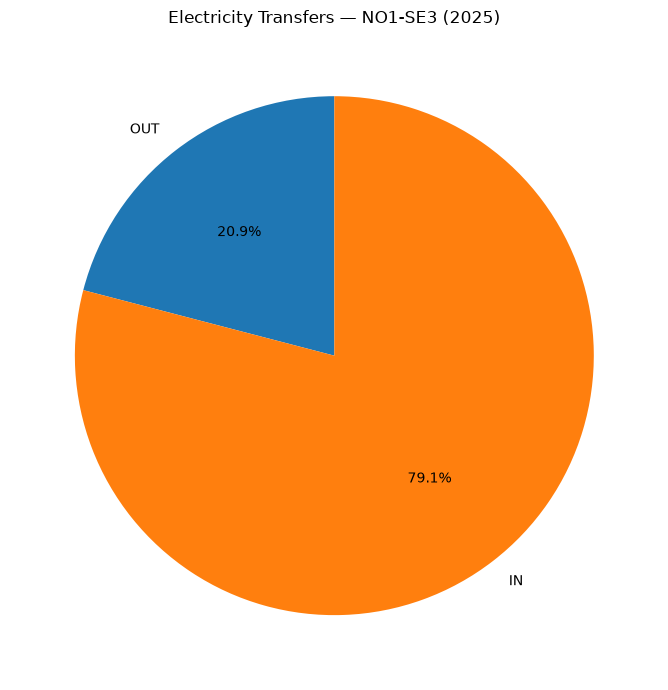

In [16]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

year = 2025
connection = "NO1-SE3"

df_year = df_cassandra.filter(
    (F.year("timestamp") == year) &
    (F.col("connection") == connection)
)

df_pie = (
    df_year
    .groupBy("direction")
    .agg(F.sum("energy_mwh").alias("total_mwh"))
    .toPandas()
)

display(df_pie)

plt.figure(figsize=(7, 7))

plt.pie(
    df_pie["total_mwh"],
    labels=df_pie["direction"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title(f"Electricity Transfers — {connection} ({year})")
plt.tight_layout()
plt.show()

### 4.6 Line Plot — Monthly Electricity Transfers

This line plot shows electricity transfers during the first month of 2025 for the NO1–SE3 connection.

The data is aggregated by day using Spark, with separate lines for electricity transferred into and out of Norway.

,date,direction,total_mwh
0,2025-01-01,IN,45789.930
1,2025-01-01,OUT,0.000
2,2025-01-02,IN,12046.055
3,2025-01-02,OUT,2090.190
4,2025-01-03,IN,6397.650


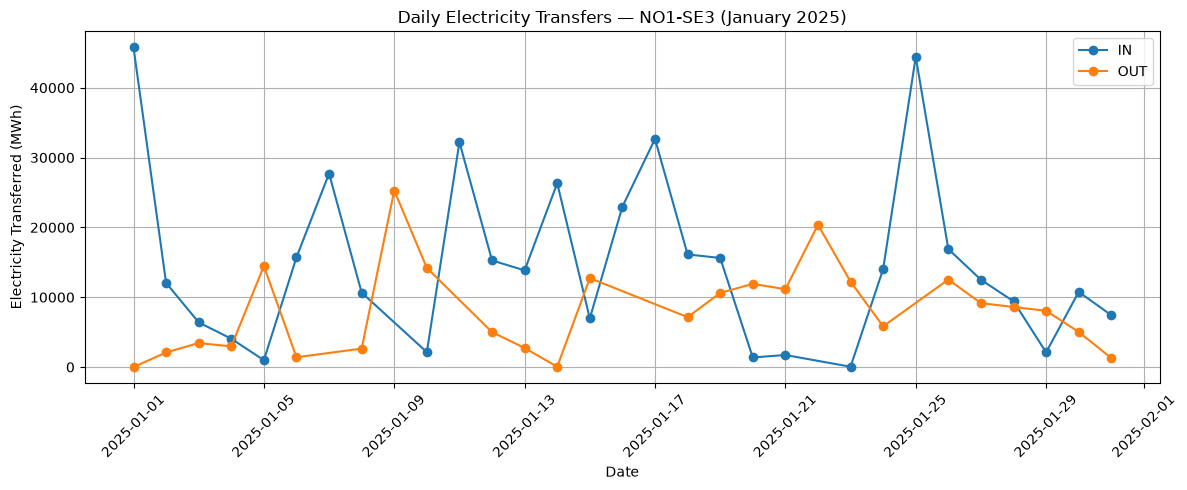

In [17]:
df_month = df_cassandra.filter(
    (F.year("timestamp") == 2025) &
    (F.month("timestamp") == 1) &
    (F.col("connection") == "NO1-SE3")
)

df_daily = (
    df_month
    .groupBy(
        F.to_date("timestamp").alias("date"),
        "direction"
    )
    .agg(F.sum("energy_mwh").alias("total_mwh"))
    .orderBy("date")
    .toPandas()
)

display(df_daily.head())

plt.figure(figsize=(12, 5))

for direction in ["IN", "OUT"]:
    subset = df_daily[df_daily["direction"] == direction]

    plt.plot(
        subset["date"],
        subset["total_mwh"],
        marker="o",
        label=direction
    )

plt.title("Daily Electricity Transfers — NO1-SE3 (January 2025)")
plt.xlabel("Date")
plt.ylabel("Electricity Transferred (MWh)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 4.7 Upload Processed Data to MongoDB

The electricity transfer data is retrieved from Cassandra and processed using Spark.

The processed data is stored in MongoDB Atlas, allowing the Streamlit application to access it without connecting directly to Cassandra.

In [ ]:
df_processed = (
    df_cassandra
    .groupBy(
        F.to_date("timestamp").alias("date"),
        "connection",
        "direction"
    )
    .agg(
        F.sum("energy_mwh").alias("total_mwh")
    )
    .orderBy("date", "connection", "direction")
)

df_processed.show(5)

print("Processed rows:", df_processed.count())

+----------+----------+---------+------------------+
|      date|connection|direction|         total_mwh|
+----------+----------+---------+------------------+
|2024-10-01|   NO1-SE3|       IN|15541.834999999997|
|2024-10-01|   NO1-SE3|      OUT|1805.7400000000002|
|2024-10-02|   NO1-SE3|       IN|10623.579999999998|
|2024-10-02|   NO1-SE3|      OUT| 4245.900000000001|
|2024-10-03|   NO1-SE3|       IN|11799.595000000001|
+----------+----------+---------+------------------+
only showing top 5 rows

Processed rows: 1213


In [19]:
df_mongo = df_processed.toPandas()

df_mongo["date"] = pd.to_datetime(df_mongo["date"])

documents = df_mongo.to_dict("records")

print("Documents prepared:", len(documents))
display(df_mongo.head())

Documents prepared: 1213


,date,connection,direction,total_mwh
0,2024-10-01,NO1-SE3,IN,15541.835
1,2024-10-01,NO1-SE3,OUT,1805.740
2,2024-10-02,NO1-SE3,IN,10623.580
3,2024-10-02,NO1-SE3,OUT,4245.900
4,2024-10-03,NO1-SE3,IN,11799.595


In [20]:
collection = db["electricity_transfers"]

collection.delete_many({})

if documents:
    collection.insert_many(documents)

print("Documents in MongoDB:", collection.count_documents({}))

Documents in MongoDB: 1213


In [21]:
sample = collection.find_one({}, {"_id": 0})

print("MongoDB sample document:")
print(sample)

print("Available connections:")
print(collection.distinct("connection"))

print("Available directions:")
print(collection.distinct("direction"))

MongoDB sample document:
{'date': datetime.datetime(2024, 10, 1, 0, 0), 'connection': 'NO1-SE3', 'direction': 'IN', 'total_mwh': 15541.834999999997}
Available connections:
['NO1-SE3']
Available directions:
['IN', 'OUT']


### 4.8 Additional Cross-Border Connections

The analysis is extended to include the NO2–DK1 connection between Norway and Denmark. Electricity flows are retrieved in both directions for the same two-year period.

In [22]:
NO2 = "10YNO-2--------T"
DK1 = "10YDK-1--------W"

additional_responses = []

for direction, source, destination in [
    ("IN", DK1, NO2),
    ("OUT", NO2, DK1)
]:
    for start, end in zip(periods[:-1], periods[1:]):
        params = {
            "securityToken": token,
            "documentType": "A11",
            "in_Domain": destination,
            "out_Domain": source,
            "periodStart": start.strftime("%Y%m%d%H%M"),
            "periodEnd": end.strftime("%Y%m%d%H%M")
        }

        response = requests.get(url, params=params, timeout=60)

        if response.status_code == 200:
            additional_responses.append({
                "direction": direction,
                "connection": "NO2-DK1",
                "start": start,
                "xml": response.content
            })
        else:
            print(direction, start.strftime("%Y-%m"), response.status_code)
            print(response.text[:200])

print("Successful downloads:", len(additional_responses), "/ 48")

Successful downloads: 48 / 48


### 4.9 Process Additional Connection Data

The XML responses for the NO2–DK1 connection are parsed into a DataFrame containing timestamps, transfer directions, power and energy values.

In [23]:
additional_records = []

for item in additional_responses:
    root = ET.fromstring(item["xml"])
    ns = {"e": root.tag.split("}")[0].strip("{")}

    for series in root.findall(".//e:TimeSeries", ns):
        for period in series.findall("e:Period", ns):
            start_text = period.findtext(
                "e:timeInterval/e:start", namespaces=ns
            )
            resolution = period.findtext("e:resolution", namespaces=ns)

            if not start_text or not resolution:
                continue

            start = pd.Timestamp(start_text)
            interval = pd.Timedelta(resolution)

            for point in period.findall("e:Point", ns):
                position = point.findtext("e:position", namespaces=ns)
                quantity = point.findtext("e:quantity", namespaces=ns)

                if position is None or quantity is None:
                    continue

                timestamp = start + (int(position) - 1) * interval
                power_mw = float(quantity)

                additional_records.append({
                    "timestamp": timestamp,
                    "connection": item["connection"],
                    "direction": item["direction"],
                    "power_mw": power_mw,
                    "energy_mwh": power_mw * interval.total_seconds() / 3600
                })

df_additional = pd.DataFrame(additional_records)

if df_additional.empty:
    raise ValueError("No observations parsed for NO2-DK1.")

df_additional = (
    df_additional
    .drop_duplicates(subset=["timestamp", "connection", "direction"])
    .sort_values(["timestamp", "direction"])
    .reset_index(drop=True)
)

print("NO2-DK1 observations:", len(df_additional))
display(df_additional.head())

NO2-DK1 observations: 58731


,timestamp,connection,direction,power_mw,energy_mwh
0,2024-10-01 00:00:00+00:00,NO2-DK1,IN,1111.7300,1111.7300
1,2024-10-01 00:00:00+00:00,NO2-DK1,OUT,0.0000,0.0000
2,2024-10-01 01:00:00+00:00,NO2-DK1,IN,1222.0750,1222.0750
3,2024-10-01 02:00:00+00:00,NO2-DK1,IN,1331.9650,1331.9650
4,2024-10-01 03:00:00+00:00,NO2-DK1,IN,1082.5675,1082.5675


### 4.10 Store Additional Connection Data in Cassandra

The additional electricity transfer observations are converted into a Spark DataFrame and appended to the existing Cassandra table.

In [24]:
df_additional_spark = spark.createDataFrame(df_additional)

df_additional_spark = df_additional_spark.withColumn(
    "timestamp",
    F.col("timestamp").cast("timestamp")
)

(
    df_additional_spark.write
    .format("org.apache.spark.sql.cassandra")
    .mode("append")
    .options(
        table="electricity_transfers",
        keyspace="ind320"
    )
    .save()
)

print("NO2-DK1 data written to Cassandra")

NO2-DK1 data written to Cassandra


In [25]:
df_cassandra = (
    spark.read
    .format("org.apache.spark.sql.cassandra")
    .options(
        table="electricity_transfers",
        keyspace="ind320"
    )
    .load()
)

df_cassandra.groupBy("connection", "direction").count().show()

+----------+---------+-----+
|connection|direction|count|
+----------+---------+-----+
|   NO2-DK1|       IN|18368|
|   NO2-DK1|      OUT|40357|
|   NO1-SE3|      OUT|12536|
|   NO1-SE3|       IN|33447|
+----------+---------+-----+



### 4.11 Update MongoDB with Additional Connections

Spark aggregates the electricity transfers into daily totals. MongoDB is updated so the Streamlit application can display both connections.

In [26]:
df_processed = (
    df_cassandra
    .groupBy(
        F.to_date("timestamp").alias("date"),
        "connection",
        "direction"
    )
    .agg(F.sum("energy_mwh").alias("total_mwh"))
)

df_mongo = df_processed.toPandas()
df_mongo["date"] = pd.to_datetime(df_mongo["date"])

documents = df_mongo.to_dict("records")

collection = db["electricity_transfers"]

collection.delete_many({})

if documents:
    collection.insert_many(documents)

print("MongoDB documents:", collection.count_documents({}))
print("Connections:", collection.distinct("connection"))

MongoDB documents: 2464
Connections: ['NO1-SE3', 'NO2-DK1']


### 4.12 Compare Electricity Transfers Across Connections

This plot compares electricity transfers during January 2025 for the NO1–SE3 and NO2–DK1 connections.

Spark is used to aggregate electricity transfers by date, connection and direction. Each connection and direction is displayed as a separate line.

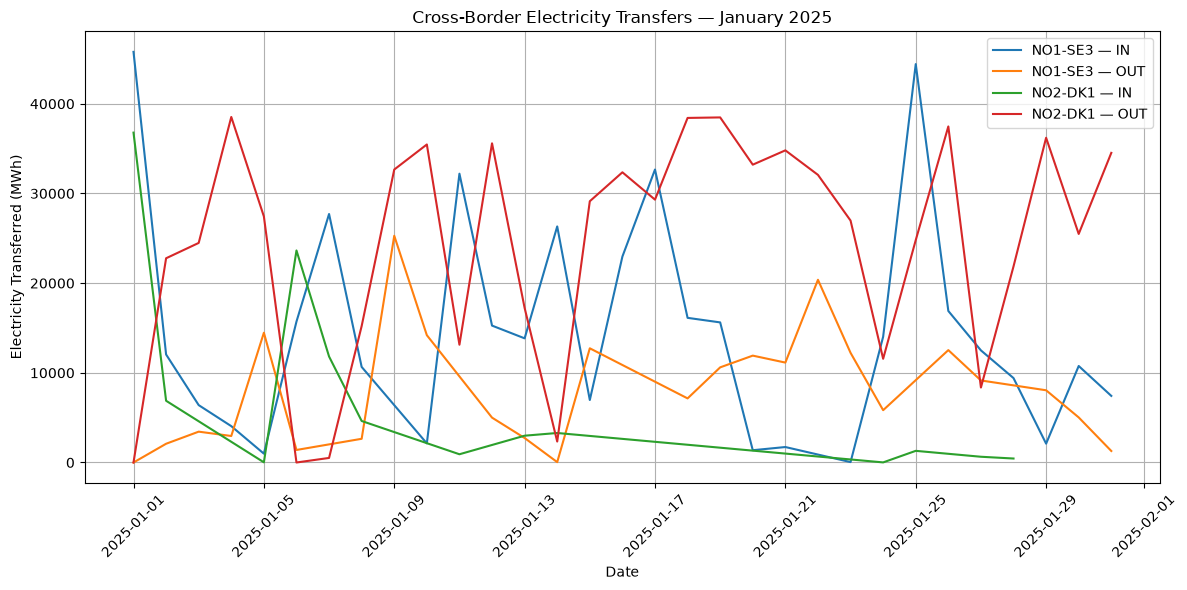

----------------------------------------
Exception occurred during processing of request from ('127.0.0.1', 64124)
Traceback (most recent call last):
  File "C:\Users\prach\AppData\Local\Programs\Python\Python311\Lib\socketserver.py", line 317, in _handle_request_noblock
    self.process_request(request, client_address)
  File "C:\Users\prach\AppData\Local\Programs\Python\Python311\Lib\socketserver.py", line 348, in process_request
    self.finish_request(request, client_address)
  File "C:\Users\prach\AppData\Local\Programs\Python\Python311\Lib\socketserver.py", line 361, in finish_request
    self.RequestHandlerClass(request, client_address, self)
  File "C:\Users\prach\AppData\Local\Programs\Python\Python311\Lib\socketserver.py", line 755, in __init__
    self.handle()
  File "c:\Projects\IND320\.venv\Lib\site-packages\pyspark\accumulators.py", line 295, in handle
    poll(accum_updates)
  File "c:\Projects\IND320\.venv\Lib\site-packages\pyspark\accumulators.py", line 267, in poll
 

In [27]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

df_comparison = (
    df_cassandra
    .filter(
        (F.year("timestamp") == 2025) &
        (F.month("timestamp") == 1)
    )
    .groupBy(
        F.to_date("timestamp").alias("date"),
        "connection",
        "direction"
    )
    .agg(F.sum("energy_mwh").alias("total_mwh"))
    .orderBy("date")
    .toPandas()
)

plt.figure(figsize=(12, 6))

for (connection, direction), group in df_comparison.groupby(
    ["connection", "direction"]
):
    plt.plot(
        group["date"],
        group["total_mwh"],
        label=f"{connection} — {direction}"
    )

plt.title("Cross-Border Electricity Transfers — January 2025")
plt.xlabel("Date")
plt.ylabel("Electricity Transferred (MWh)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 7. Work Log

For Assignment 2, I continued developing the IND320 project by working with Apache Spark, Cassandra, MongoDB Atlas, Jupyter Notebook and Streamlit. The main objective was to retrieve electricity data from APIs, process and store the data in databases, and visualize the results in an interactive application.

I started by setting up and testing the connection between Spark and Cassandra. This was one of the more challenging parts of the assignment because I experienced several problems with Docker, Cassandra configuration and Spark. I had to check whether the Cassandra container was running correctly and make sure that Spark was using the correct Python environment. After troubleshooting these issues, I managed to establish a working connection and read and write data using Spark. One of the main problems I faced was that Spark only worked with Python 3.11 and not 3.12 whihc i had installed in the first place. Finding this out was one of the timetaking challenges of this task. 

I also connected Python to MongoDB Atlas. I tested the database connection and performed basic CRUD operations to understand how documents could be inserted, retrieved, updated and deleted. I stored the MongoDB connection string in a local environment file to avoid exposing sensitive information in the GitHub repository.

Next, I worked with the NVE Magasinstatistikk API to retrieve Norwegian reservoir statistics. I used Pandas to prepare the data and Matplotlib to visualize reservoir filling levels. I also updated the Streamlit application to make the data easier to explore through interactive selections.

The largest part of the assignment involved retrieving cross-border electricity transfer data from the ENTSO-E API. I downloaded two years of data for connections between Norway and Sweden and between Norway and Denmark. Since the API returned XML data, I had to extract the relevant information and convert it into DataFrames. I then used Spark to store the observations in Cassandra and calculate daily electricity transfer totals. The processed data was uploaded to MongoDB Atlas.

I created pie charts to compare electricity imports and exports, as well as line plots to visualize electricity transfers over time. These visualizations were also implemented in Streamlit, where users can select connections, years and months.



## 8. AI Usage

I used ChatGPT as a supporting tool throughout Assignment 2, mainly for understanding technical concepts, debugging errors and improving my code.

AI assistance was particularly useful when troubleshooting the Cassandra and Spark connection, including problems related to Docker configuration, Python environments and database connectivity. I also used ChatGPT to understand how to retrieve data from the NVE and ENTSO-E APIs, parse XML responses, and process the data using Pandas and PySpark.

During the development of the Streamlit application, I used AI to help write and modify code for interactive visualizations, database connections and user interface components. ChatGPT also helped me identify errors, suggest possible solutions and organize the Jupyter Notebook into a clearer structure.

AI-generated code was tested and adjusted in my local development environment. I reviewed the outputs and used the results to check whether the different components worked as expected.

I also used ChatGPT to help improve the written documentation, including the work log and AI usage description.